In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
from urllib.parse import urlencode
warnings.filterwarnings('ignore')

from meteostat import Point, Daily
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib
import optuna


In [ ]:
START_YEAR = 2021
END_YEAR = 2023

# Water Quality Portal (WQP) Data - California, USA

base_url = "https://www.waterqualitydata.us/data/Result/search"
params = [
    ('statecode', 'US:06'), # California
    ('startDateLo', f'01-01-{START_YEAR}'),
    ('startDateHi', f'12-31-{END_YEAR}'),
    ('characteristicName', 'pH'),
    ('characteristicName', 'Specific conductance'),
    ('characteristicName', 'Turbidity'),
    ('characteristicName', 'Dissolved oxygen (DO)'),
    ('characteristicName', 'Temperature, water'),
    ('characteristicName', 'Escherichia coli'),
    ('mimeType', 'csv')
]

df_wqp = pd.read_csv(f"{base_url}?{urlencode(params)}", low_memory=False)

# Select relevant columns and clean invalid numeric records
cols_to_keep = ['ActivityStartDate', 'MonitoringLocationIdentifier', 'CharacteristicName', 'ResultMeasureValue']
df_wqp = df_wqp[[c for c in cols_to_keep if c in df_wqp.columns]].copy()
df_wqp['ResultMeasureValue'] = pd.to_numeric(df_wqp['ResultMeasureValue'], errors='coerce')
df_wqp = df_wqp.dropna(subset=['ResultMeasureValue', 'ActivityStartDate'])
df_wqp['ActivityStartDate'] = pd.to_datetime(df_wqp['ActivityStartDate'])

# Pivot the table to reshape parameters into individual feature columns
df_pivot = df_wqp.pivot_table(
    index=['ActivityStartDate', 'MonitoringLocationIdentifier'],
    columns='CharacteristicName',
    values='ResultMeasureValue',
    aggfunc='mean'
).reset_index()

# Standardize feature column names
df_pivot.rename(columns={
    'Specific conductance': 'Conductivity',
    'Dissolved oxygen (DO)': 'DO',
    'Temperature, water': 'Water_Temp',
    'Escherichia coli': 'E_Coli'
}, inplace=True)

# METEOSTAT WEATHER DATA 

print(f"Fetching weather data ({START_YEAR}-{END_YEAR})...")
location = Point(36.7782, -119.4179, 10)
weather = Daily(location, datetime(START_YEAR, 1, 1), datetime(END_YEAR, 12, 31)).fetch().reset_index()
weather = weather[['time', 'tavg', 'prcp']].copy()
weather.rename(columns={'time': 'ActivityStartDate', 'tavg': 'Temp_C', 'prcp': 'Rain_mm'}, inplace=True)
weather['Rain_mm'] = weather['Rain_mm'].fillna(0.0)

# Merge water quality parameters with synchronized meteorological data
df_eda = pd.merge(df_pivot, weather, on='ActivityStartDate', how='inner')
df_eda = df_eda.dropna(subset=['E_Coli']).copy()

# QUALITY FILTER (MINIMUM 2 ACTIVE SENSORS)

sensor_cols = ['pH', 'Conductivity', 'Turbidity', 'DO', 'Water_Temp']
df_eda = df_eda.dropna(subset=sensor_cols, thresh=2).copy()

print(f"\n-> Cleaned Dataset Shape: {df_eda.shape}")

# Missing Values Summary
missing_summary = pd.DataFrame({
    'Missing Values Count': df_eda.isnull().sum(),
    'Missing Ratio (%)': (df_eda.isnull().mean() * 100).round(2)
})
print("\n--- MISSING VALUE RATIOS ---")
display(missing_summary)

1/3: Fetching WQP data (2021-2023)... (Waiting for server response)
2/3: Fetching weather data (2021-2023)...

-> Cleaned Dataset Shape: (1292, 10)

--- UPDATED MISSING VALUE RATIOS ---


,Missing Values Count,Missing Ratio (%)
ActivityStartDate,0,0.00
MonitoringLocationIdentifier,0,0.00
DO,69,5.34
E_Coli,0,0.00
Conductivity,314,24.30
Water_Temp,38,2.94
Turbidity,71,5.50
pH,116,8.98
Temp_C,0,0.00
Rain_mm,0,0.00


Target Class Distribution:
Is_Potable
0    704
1    588
Name: count, dtype: int64


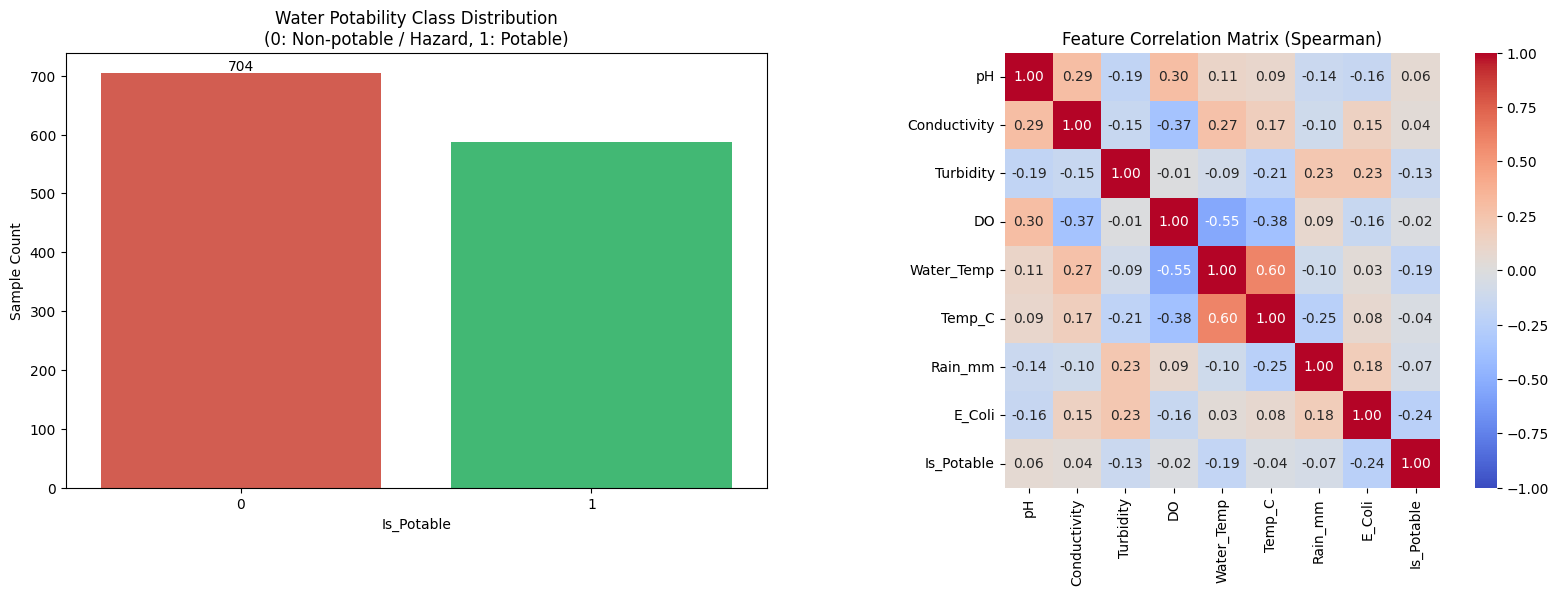

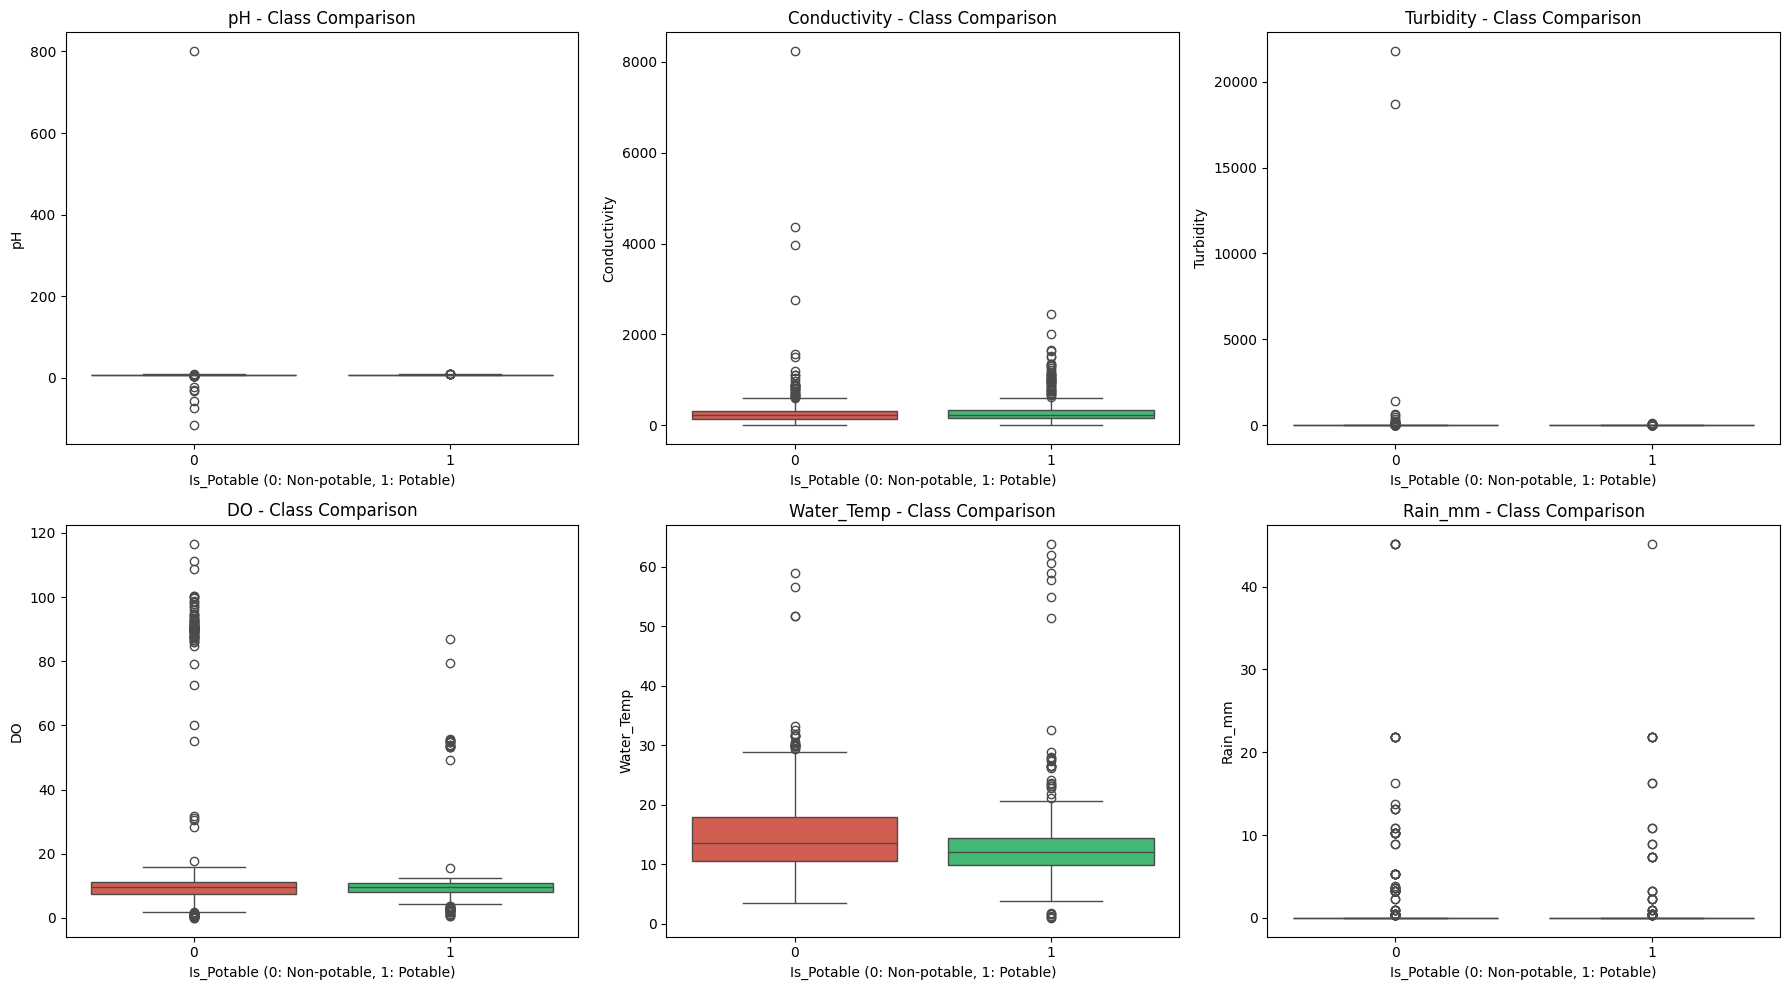

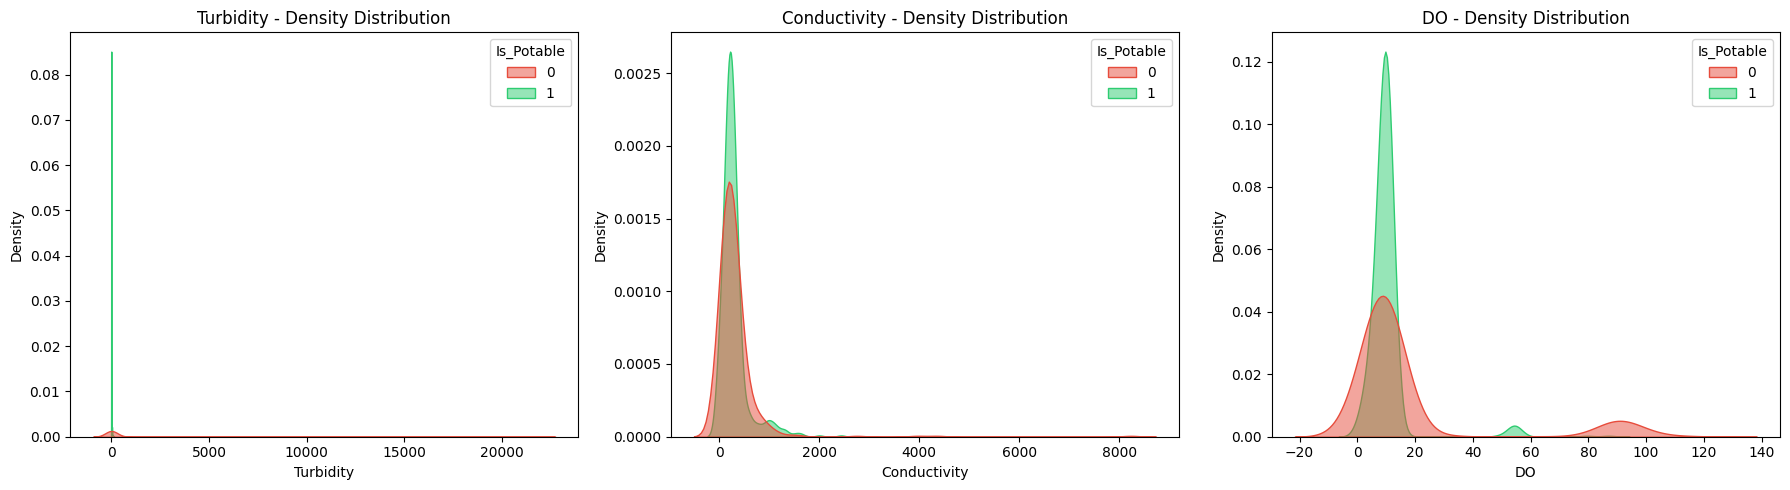

In [ ]:
# Multi-criteria labeling (Target variable definition based on WHO & TS 266 standards)
cond_ecoli = df_eda['E_Coli'] <= 126.0
cond_ph = df_eda['pH'].between(6.5, 9.5)
cond_cond = df_eda['Conductivity'] <= 2500
df_eda['Is_Potable'] = (cond_ecoli & cond_ph & cond_cond).astype(int)

print(f"Target Class Distribution:\n{df_eda['Is_Potable'].value_counts()}")


# EXPLORATORY DATA ANALYSIS - OVERVIEW

plt.figure(figsize=(16, 6))

# Plot 1: Target Class Balance
plt.subplot(1, 2, 1)
ax = sns.countplot(data=df_eda, x='Is_Potable', palette=['#e74c3c', '#2ecc71'])
plt.title('Water Potability Class Distribution\n(0: Non-potable / Hazard, 1: Potable)')
plt.xlabel('Is_Potable')
plt.ylabel('Sample Count')
ax.bar_label(ax.containers[0])

# Plot 2: Correlation Matrix 
plt.subplot(1, 2, 2)
corr_cols = ['pH', 'Conductivity', 'Turbidity', 'DO', 'Water_Temp', 'Temp_C', 'Rain_mm', 'E_Coli', 'Is_Potable']
corr_cols = [c for c in corr_cols if c in df_eda.columns]

# Spearman correlation is utilized to handle non-normal environmental sensor distributions
corr_matrix = df_eda[corr_cols].corr(method='spearman') 
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title('Feature Correlation Matrix (Spearman)')

plt.tight_layout()
plt.show()


# BOXPLOTS - CLASS-BASED SENSOR COMPARISONS

features_to_plot = ['pH', 'Conductivity', 'Turbidity', 'DO', 'Water_Temp', 'Rain_mm']

plt.figure(figsize=(18, 10))
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 3, i)
    # showfliers=False can be added to focus on interquartile ranges without extreme noise
    sns.boxplot(data=df_eda, x='Is_Potable', y=col, palette=['#e74c3c', '#2ecc71'])
    plt.title(f'{col} - Class Comparison')
    plt.xlabel('Is_Potable (0: Non-potable, 1: Potable)')
    
plt.tight_layout()
plt.show()

# DENSITY PLOTS (KDE) - DISTRIBUTION & SKEWNESS ANALYSIS

plt.figure(figsize=(18, 5))
cols_kde = ['Turbidity', 'Conductivity', 'DO']

for i, col in enumerate(cols_kde, 1):
    plt.subplot(1, 3, i)
    sns.kdeplot(
        data=df_eda, 
        x=col, 
        hue='Is_Potable', 
        fill=True, 
        common_norm=False, 
        palette=['#e74c3c', '#2ecc71'], 
        alpha=0.5)
    
    plt.title(f'{col} - Density Distribution')
    plt.xlabel(col)

plt.tight_layout()
plt.show()

In [ ]:
# FEATURE SELECTION & TARGET VARIABLE

# E_Coli is excluded from the input features as it was used to define the target variable
feature_cols = ['pH', 'Conductivity', 'Turbidity', 'DO', 'Water_Temp', 'Temp_C', 'Rain_mm']
X = df_eda[feature_cols]
y = df_eda['Is_Potable']

 
# TRAIN-TEST SPLIT

# 'stratify=y' ensures balanced class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


# MISSING VALUE IMPUTATION

imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=feature_cols, index=X_test.index)


# BAYESIAN HYPERPARAMETER OPTIMIZATION (OPTUNA)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        # Adjusting weight balance to better capture hazardous waters (Class 0)
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 3.0),
        'random_state': 42,
        'eval_metric': 'logloss'
    }
    
    model_cv = xgb.XGBClassifier(**params)
    
    # 5-Fold Cross-Validation to prevent overfitting
    score = cross_val_score(model_cv, X_train_imp, y_train, cv=5, scoring='roc_auc').mean()
    return score


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20) 

print("\nBest Hyperparameters Found:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# FINAL MODEL TRAINING WITH BEST PARAMETERS

best_params = study.best_params
best_params['random_state'] = 42
best_params['eval_metric'] = 'logloss'

clf_optimized = xgb.XGBClassifier(**best_params)
clf_optimized.fit(X_train_imp, y_train)

# PREDICTIONS AND PERFORMANCE EVALUATION

y_pred_opt = clf_optimized.predict(X_test_imp)
y_prob_opt = clf_optimized.predict_proba(X_test_imp)[:, 1]

print("\n" + "=" * 60)
print("--- OPTIMIZED XGBOOST MODEL PERFORMANCE (DISASTER SCENARIO) ---")
print("=" * 60)
print(classification_report(y_test, y_pred_opt))
print(f"Optimized XGBoost ROC-AUC Score: {roc_auc_score(y_test, y_prob_opt):.4f}")

# SAVE MODEL ARTIFACTS FOR DEPLOYMENT

model_artifacts_opt = {
    'model': clf_optimized,
    'imputer': imputer,
    'features': feature_cols
}
joblib.dump(model_artifacts_opt, 'aquasafe_xgboost_model.pkl')
print("\n-> Optimized model successfully saved to disk as 'aquasafe_xgboost_model.pkl'.")

[I 2026-10-29 21:19:22,731] A new study created in memory with name: no-name-140443d7-4661-42f7-a488-6789c5469673


Starting Bayesian Optimization with Optuna... (This may take 30-40 seconds)



[I 2026-10-29 21:19:25,202] Trial 0 finished with value: 0.9020624310729752 and parameters: {'n_estimators': 176, 'max_depth': 8, 'learning_rate': 0.023982638915083898, 'scale_pos_weight': 2.2305363525598834}. Best is trial 0 with value: 0.9020624310729752.
[I 2026-10-29 21:19:26,374] Trial 1 finished with value: 0.9034102065793366 and parameters: {'n_estimators': 236, 'max_depth': 9, 'learning_rate': 0.17480006174889895, 'scale_pos_weight': 2.2603779800882937}. Best is trial 1 with value: 0.9034102065793366.
[I 2026-10-29 21:19:27,105] Trial 2 finished with value: 0.9015891882077629 and parameters: {'n_estimators': 261, 'max_depth': 4, 'learning_rate': 0.0818961011427856, 'scale_pos_weight': 1.1786943966117363}. Best is trial 1 with value: 0.9034102065793366.
[I 2026-10-29 21:19:27,563] Trial 3 finished with value: 0.8979162183608145 and parameters: {'n_estimators': 118, 'max_depth': 6, 'learning_rate': 0.025933966059700865, 'scale_pos_weight': 1.216788285123425}. Best is trial 1 with


Best Hyperparameters Found:
  n_estimators: 281
  max_depth: 7
  learning_rate: 0.049580467969486564
  scale_pos_weight: 2.9054234700430785

--- OPTIMIZED XGBOOST MODEL PERFORMANCE (DISASTER SCENARIO) ---
              precision    recall  f1-score   support

           0       0.90      0.81      0.85       141
           1       0.80      0.90      0.84       118

    accuracy                           0.85       259
   macro avg       0.85      0.85      0.85       259
weighted avg       0.86      0.85      0.85       259

Optimized XGBoost ROC-AUC Score: 0.9171

-> Optimized model successfully saved to disk as 'aquasafe_xgboost_model.pkl'.
